# Cloud Workload Forecasting — Exploratory Data Analysis

**Candidate:** Adil Shamim — AI/ML Engineering Internship take-home, Atomity.

**Dataset:** `data-v1` release — a curated subset of the Microsoft Azure Public Dataset V2
(10,000 VMs × 134 five-minute CPU observations = 1,340,000 rows, ≈11.1 h per VM).

This notebook establishes what the workload represents before any modelling, following the
required work in `ASSIGNMENT.md` §3A. Every section ends with an **operational reading** —
why the finding matters for cloud infrastructure management.

## Leakage policy used throughout this notebook

**All exploratory analysis in this notebook uses only the first 110 timestamps
(the public training window).** The final 24 timestamps are the untouched
holdout: their target values are neither loaded, plotted, nor summarized here —
they are unsealed only in `03_evaluation.ipynb`, after the models are frozen.
(The release-level integrity checks in §1 verify the dataset contract as
supplied — row counts, duplicates, ranges — which is data validation, not model
development.)

- Metadata fields that encode future information (`avg_cpu`, `max_cpu`, `p95_max_cpu` —
  full-lifetime statistics — and `timestamp_vm_deleted`) are used **descriptively only**,
  never as forecasting features.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The repository package (pip install -e ".[dev]" must have been run).
import cwfc
from cwfc.data import TARGET_AGGREGATE_CPU, TARGET_ACTIVE_VM_COUNT, chronological_split, load_dataset

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO / "challenge_data"
FIG_DIR = REPO / "figures"
FIG_DIR.mkdir(exist_ok=True)

# ---- plot style: publication-quality, colour-blind friendly -------------
mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
C_TRAIN = "#1f77b4"      # blue   – training window
C_HOLD = "#ff7f0e"       # orange – holdout window (used in notebook 03 only)
C_ACC = "#2ca02c"        # green  – accent
C_CAT = ["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b3"]
PALETTE = plt.rcParams["axes.prop_cycle"].by_key()["color"]

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    print(f"saved {path.relative_to(REPO)}")

print("cwfc", cwfc.__file__)
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__)

cwfc /home/z/my-project/forecasting-challenge/src/cwfc/__init__.py
pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.9.2


## 1. Data dimensions, schema and integrity

The two release files are loaded through the preprocessing pipeline in
`src/cwfc/data.py`, which validates the schema against `DATASET.md`, detects duplicate
`(vm_id, timestamp)` records, flags invalid CPU readings, and preserves chronological
order. The loader returns a `Dataset` object with the cleaned frames, the derived target
series, and a log of every preprocessing decision taken.

In [2]:
%%time
ds = load_dataset(DATA_DIR)
cpu, meta, targets = ds.cpu, ds.metadata, ds.targets

print(ds.report())
print(f"\nCPU frame: {len(cpu):,} rows × {cpu.shape[1]} cols | metadata: {len(meta):,} rows")
cpu.head(3)

- Loaded 1,340,000 CPU rows for 10,000 VMs.
- No duplicate (vm_id, timestamp) rows found.
- All avg_cpu readings are finite and within [0, 100].
- CPU and metadata VM populations match exactly.
- Every observed timestamp has at least one valid reading.
- Modal timestamp cadence: 300 seconds.

CPU frame: 1,340,000 rows × 6 cols | metadata: 10,000 rows
CPU times: user 3.24 s, sys: 166 ms, total: 3.4 s
Wall time: 3.4 s


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu,_valid
0,0,++HH65MmT9ktdMdfSKCLk9O/VFunMJLxKrbFC64hN4zKe5...,17.230899,97.480132,44.666304,True
1,0,++ZSbZd5OJYsKufT38lazeV3bEVgYHMQuyGN3VawPvGypH...,10.664297,19.399918,14.829906,True
2,0,++zzCnbMoqo1+q/X2oYl3UilhQIQqoq0k7iRQm+74jPxzA...,4.124012,13.447978,8.286425,True


In [3]:
# Data-contract checks against DATASET.md / DATA_CARD.md guarantees
checks = pd.DataFrame({
    "check": [
        "rows == 1,340,000",
        "unique VMs == 10,000",
        "observations per VM == 134 (min == max)",
        "no duplicate (vm_id, timestamp)",
        "no missing values (CPU file)",
        "no missing values (metadata)",
        "avg_cpu within [0, 100]",
        "min_cpu ≤ avg_cpu ≤ max_cpu always",
        "CPU/metadata VM populations match",
        "134 distinct timestamps",
    ],
    "result": [
        len(cpu) == 1_340_000,
        cpu["vm_id"].nunique() == 10_000,
        cpu.groupby("vm_id").size().eq(134).all(),
        not cpu.duplicated(["vm_id", "timestamp"]).any(),
        cpu[["timestamp", "vm_id", "min_cpu", "max_cpu", "avg_cpu"]].isna().sum().sum() == 0,
        meta.isna().sum().sum() == 0,
        cpu["avg_cpu"].between(0, 100).all(),
        ((cpu["min_cpu"] <= cpu["avg_cpu"]) & (cpu["avg_cpu"] <= cpu["max_cpu"])).all(),
        set(cpu["vm_id"]) == set(meta["vm_id"]),
        targets.index.nunique() == 134,
    ],
})
checks["result"] = checks["result"].map({True: "PASS", False: "FAIL"})
display(checks.style.hide(axis="index"))

check,result
"rows == 1,340,000",PASS
"unique VMs == 10,000",PASS
observations per VM == 134 (min == max),PASS
"no duplicate (vm_id, timestamp)",PASS
no missing values (CPU file),PASS
no missing values (metadata),PASS
"avg_cpu within [0, 100]",PASS
min_cpu ≤ avg_cpu ≤ max_cpu always,PASS
CPU/metadata VM populations match,PASS
134 distinct timestamps,PASS


**Every contract check passes.** The curated release is clean by construction: the
challenge authors selected only VMs with *complete* 134-observation traces (see the bundled
`DATA_CARD.md`), so this dataset has no missing readings, no duplicates, and no
out-of-range values.

> **Operational reading.** Real production telemetry is never this clean — VMs appear and
> disappear mid-window, agents drop samples, and clock skew creates duplicate or
> out-of-order records. The preprocessing pipeline (`cwfc/data.py`) therefore still
> implements duplicate dropping, invalid-reading exclusion, and chronological sorting, and
> its behaviour is covered by unit tests with deliberately dirty synthetic data. A
> capacity-planning pipeline must fail loudly (schema violations) or degrade gracefully
> (row-level dirt), never silently mis-aggregate.

## 2. Timestamp coverage and sampling cadence

The 134 timestamps form a perfect five-minute grid: 0 s → 39,900 s (11.08 h), every
consecutive gap exactly 300 s, and every one of the 10,000 VMs has a reading at every
timestamp.

EDA scope: training window = 110 timestamps (0–32700 s) = 1,100,000 readings


saved figures/fig01_coverage_cadence.png


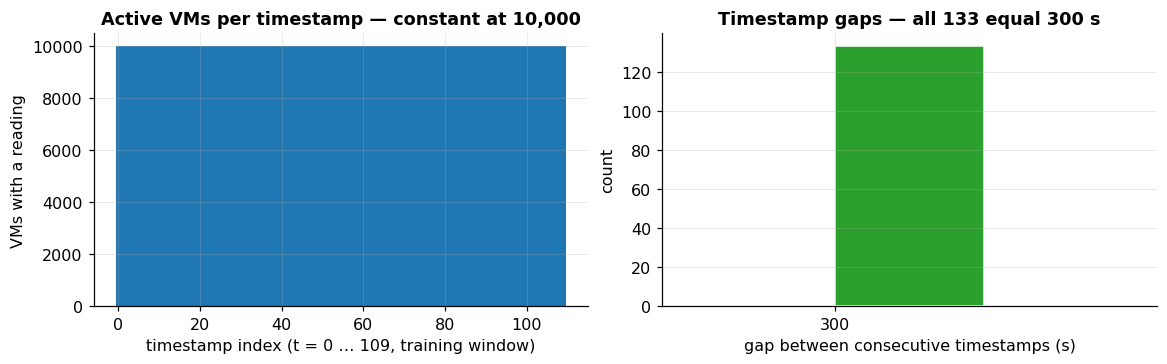

release grid: 134 timestamps | span 0–39900 s (11.08 h) | distinct gaps: [np.float64(300.0)]


In [4]:
ts = pd.Series(targets.index.to_numpy())
gaps = ts.diff().dropna()

# The official chronological split: EDA from here on uses the TRAIN side only.
train, _ = chronological_split(targets)
agg_train = train[TARGET_AGGREGATE_CPU]
# Holdout readings are excluded from all row-level analysis in this notebook.
cpu_train = cpu[cpu["timestamp"].isin(train.index)]
print(f"EDA scope: training window = {len(train)} timestamps "
      f"({train.index[0]}–{train.index[-1]} s) = {len(cpu_train):,} readings")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2), constrained_layout=True)

ax = axes[0]
per_ts_vms = cpu_train.groupby("timestamp")["vm_id"].nunique()
ax.bar(range(len(per_ts_vms)), per_ts_vms.values, width=1.0, color=C_TRAIN)
ax.set_xlabel("timestamp index (t = 0 … 109, training window)")
ax.set_ylabel("VMs with a reading")
ax.set_title("Active VMs per timestamp — constant at 10,000")

ax = axes[1]
ax.hist(gaps, bins=np.arange(299.5, 301.5, 0.5), color=C_ACC, edgecolor="white")
ax.set_xlabel("gap between consecutive timestamps (s)")
ax.set_ylabel("count")
ax.set_title(f"Timestamp gaps — all {len(gaps)} equal 300 s")
ax.set_xticks([300])
save_fig(fig, "fig01_coverage_cadence.png")
plt.show()

print(f"release grid: {len(ts)} timestamps | span {ts.iloc[0]:.0f}–{ts.iloc[-1]:.0f} s "
      f"({(ts.iloc[-1]-ts.iloc[0])/3600:.2f} h) | distinct gaps: {sorted(gaps.unique())}")

Two structural facts follow directly:

1. **`active_vm_count` is constant at 10,000.** This follows structurally, without reading
   any holdout value: the release contract (verified in §1) gives every one of the 10,000
   VMs exactly 134 observations on the shared 300-second grid, so no VM can be absent at
   any timestamp — the count cannot vary anywhere in the window.
2. The observation window is **11.08 hours — less than half a day**. Daily or weekly
   seasonality is *unidentifiable* from this data; any model assuming such seasonality
   would be extrapolating structure it cannot see.

> **Operational reading.** (1) means the challenge's `active_vm_count` target is a step
> function: the optimal forecast is the constant 10,000, and we must resist dressing that
> up as model skill. In a real fleet, active count is the *churn* signal that drives
> capacity reservations; here the curation removed it (see §4). (2) means this is a
> **short-horizon, memory-driven forecasting problem** — the only usable signal is the
> recent level of the series, not calendar structure.

## 3. CPU utilization distribution

We look at the training-window VM-level `avg_cpu` readings (110 timestamps × 10,000 VMs),
then at per-VM behaviour. Recall `avg_cpu` is the mean CPU utilization of a VM during a
five-minute interval, in percent (0–100).

saved figures/fig02_cpu_distribution.png


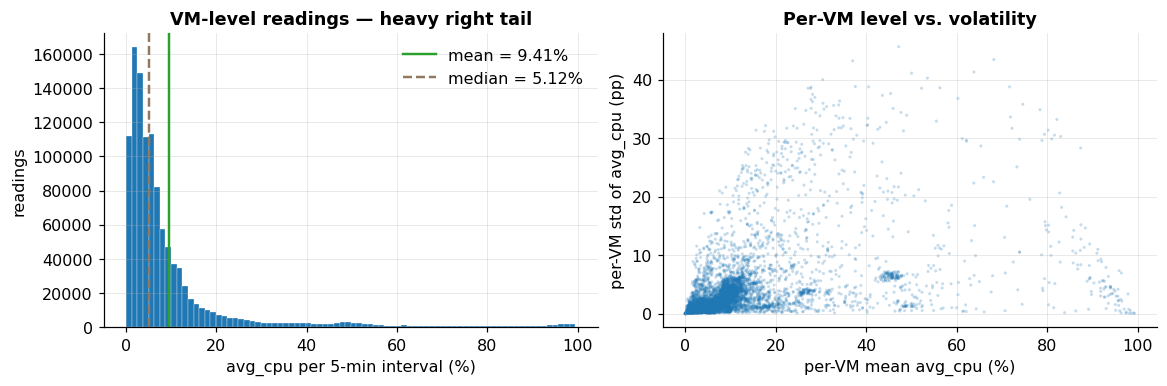

,avg_cpu (%)
count,1100000.00
mean,9.41
std,14.28
min,0.01
25%,2.49
50%,5.12
75%,9.65
90%,19.69
95%,37.29
99%,87.41


readings < 1%:        7.6%
readings > 50%:       3.1%
nearly-idle VMs (mean < 1%): 5.8%
between-VM std of means: 13.05 pp vs within-VM median std: 1.33 pp


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4), constrained_layout=True)

ax = axes[0]
ax.hist(cpu_train["avg_cpu"], bins=80, color=C_TRAIN, edgecolor="white", linewidth=0.2)
ax.axvline(cpu_train["avg_cpu"].mean(), color=C_ACC, lw=1.6,
           label=f"mean = {cpu_train['avg_cpu'].mean():.2f}%")
ax.axvline(cpu_train["avg_cpu"].median(), color="#937860", lw=1.6, ls="--",
           label=f"median = {cpu_train['avg_cpu'].median():.2f}%")
ax.set_xlabel("avg_cpu per 5-min interval (%)")
ax.set_ylabel("readings")
ax.set_title("VM-level readings — heavy right tail")
ax.legend()

ax = axes[1]
vm_mean = cpu_train.groupby("vm_id")["avg_cpu"].mean()
vm_std = cpu_train.groupby("vm_id")["avg_cpu"].std()
ax.scatter(vm_mean, vm_std, s=4, alpha=0.25, color=C_TRAIN, edgecolors="none")
ax.set_xlabel("per-VM mean avg_cpu (%)")
ax.set_ylabel("per-VM std of avg_cpu (pp)")
ax.set_title("Per-VM level vs. volatility")
save_fig(fig, "fig02_cpu_distribution.png")
plt.show()

q = cpu_train["avg_cpu"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2).to_frame("avg_cpu (%)")
display(q)
print(f"readings < 1%:        {(cpu_train['avg_cpu'] < 1).mean():.1%}")
print(f"readings > 50%:       {(cpu_train['avg_cpu'] > 50).mean():.1%}")
print(f"nearly-idle VMs (mean < 1%): {(vm_mean < 1).mean():.1%}")
print(f"between-VM std of means: {vm_mean.std():.2f} pp vs within-VM median std: {vm_std.median():.2f} pp")

The fleet is **strongly heterogeneous and right-skewed**: half of all readings are
below 5.1%, yet 3% exceed 50% and the p99 is 87%. Per-VM behaviour splits into a large
low-utilization majority and a small group of hot VMs that saturate their cores.
Crucially, **between-VM differences (std of VM means ≈ 13 pp) are an order of magnitude
larger than within-VM fluctuations (median VM std ≈ 1.3 pp)**.

> **Operational reading.** The aggregate fleet utilization is a law-of-large-numbers
> average over 10,000 heterogeneous VMs — that is *why* it is so stable (§6) and hence
> forecastable. For bin-packing and autoscaling the tail matters more than the mean: 3%
> of readings above 50% CPU concentrate in a small set of VMs, so per-node headroom
> policy must be driven by the per-VM distribution, not the fleet mean. A small number of
> "noisy neighbours" (hot VMs) dominate contention risk on shared hosts.

## 4. VM lifetimes and churn

`timestamp_vm_created` is 0 for **all** VMs (in the upstream Azure V2 semantics this marks
VMs that already existed when the trace started), and `timestamp_vm_deleted` records when
each VM was deleted. These fields are **metadata for description only** — a deletion
timestamp is future information at forecast time and is never used as a feature.

saved figures/fig03_lifetimes.png


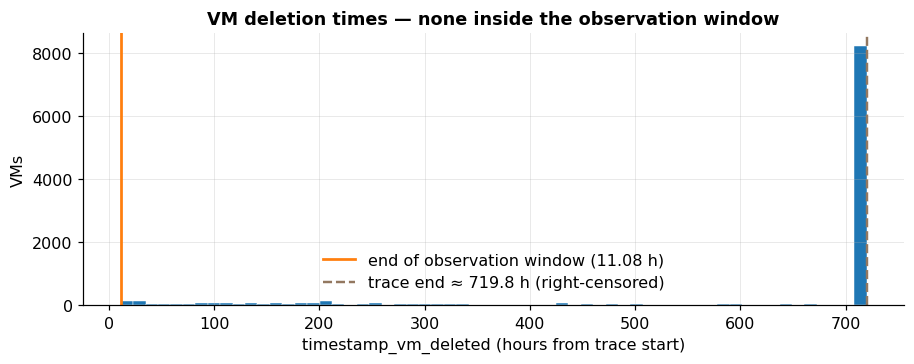

VMs deleted inside the 11.08 h window: 0
VMs deleted within 1 h after the window: 7
VMs still alive at trace end (right-censored): 8,213


In [6]:
fig, ax = plt.subplots(figsize=(8.2, 3.2), constrained_layout=True)
del_h = meta["timestamp_vm_deleted"] / 3600.0
ax.hist(del_h, bins=60, color=C_TRAIN, edgecolor="white", linewidth=0.3)
ax.axvline(11.08, color=C_HOLD, lw=1.8, label="end of observation window (11.08 h)")
ax.axvline(719.8, color="#937860", lw=1.6, ls="--",
           label="trace end ≈ 719.8 h (right-censored)")
ax.set_xlabel("timestamp_vm_deleted (hours from trace start)")
ax.set_ylabel("VMs")
ax.set_title("VM deletion times — none inside the observation window")
ax.legend()
save_fig(fig, "fig03_lifetimes.png")
plt.show()

within = int((meta["timestamp_vm_deleted"] <= 39900).sum())
print(f"VMs deleted inside the 11.08 h window: {within}")
print(f"VMs deleted within 1 h after the window: {int(((meta['timestamp_vm_deleted'] > 39900) & (meta['timestamp_vm_deleted'] <= 39900 + 3600)).sum())}")
print(f"VMs still alive at trace end (right-censored): {(meta['timestamp_vm_deleted'] == 2591400).sum():,}")

No VM is deleted during the observation window; the earliest deletion is 600 s after
the window ends, and 82% of VMs are still alive at the 30-day trace end. **Within this
dataset there is no churn signal at all** — the constant `active_vm_count` of §2 is the
direct consequence.

> **Operational reading.** This is a *curation artefact*, not cloud reality: the release
> deliberately kept only complete 134-observation traces. We therefore: (i) forecast
> `active_vm_count` with the constant population (which is provably optimal here), and
> (ii) explicitly document that in production the active-count series is driven by
> provisioning/deletion events and would need churn-aware modelling (e.g. survival or
> count models). The submission pipeline still computes the count honestly from the data
> rather than hard-coding 10,000, so it generalizes to datasets that *do* churn.

## 5. Workload categories and VM shapes

The metadata carries three static segmentations: `vm_category` (workload class),
`virtual_core_bucket` and `memory_gb_bucket`. Unlike the lifetime statistics, these are
properties known when a VM is provisioned, so they are legitimate segmenting dimensions
(and could serve as forecasting features for segment-level models).

saved figures/fig04_segments.png


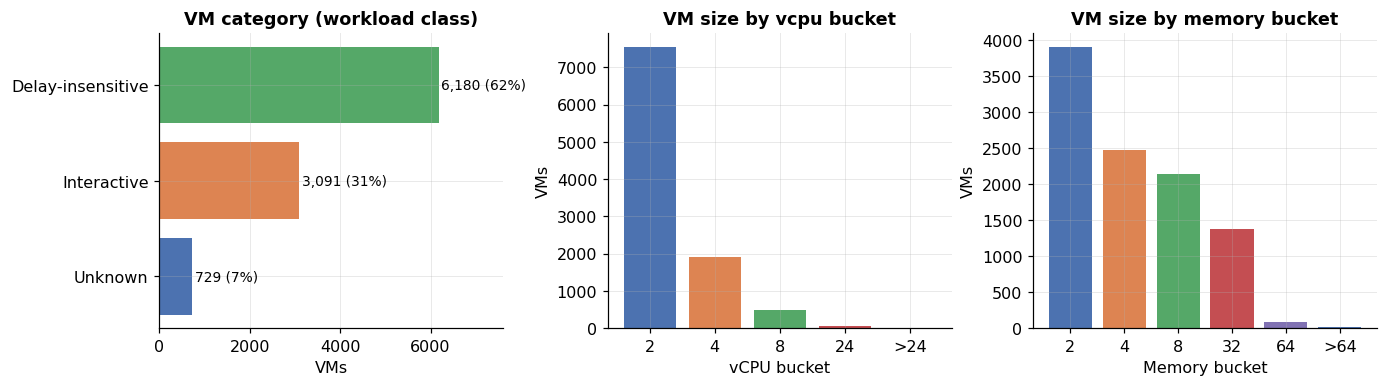

,VMs,mean_avg_cpu,mean_p95_max_cpu
vm_category,,,
Delay-insensitive,6180,8.17,37.11
Interactive,3091,11.44,35.64
Unknown,729,10.39,33.09


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4), constrained_layout=True)

order = meta["vm_category"].value_counts().index
counts = meta["vm_category"].value_counts().loc[order]
axes[0].barh(order[::-1], counts.loc[order[::-1]], color=C_CAT[:3])
for i, (cat, n) in enumerate(counts.loc[order[::-1]].items()):
    axes[0].text(n + 60, i, f"{n:,} ({n/len(meta):.0%})", va="center", fontsize=9)
axes[0].set_xlim(0, 7600)
axes[0].set_xlabel("VMs")
axes[0].set_title("VM category (workload class)")

for ax, col, title in (
    (axes[1], "virtual_core_bucket", "vCPU bucket"),
    (axes[2], "memory_gb_bucket", "Memory bucket"),
):
    order_b = ["2", "4", "8", "24", "64", ">24"] if col == "virtual_core_bucket" else ["2", "4", "8", "32", "64", ">64"]
    order_b = [b for b in order_b if b in set(meta[col])] 
    extra = [b for b in meta[col].unique() if b not in order_b]
    order_b = order_b + sorted(extra)
    cnt = meta[col].value_counts().reindex(order_b)
    ax.bar(range(len(order_b)), cnt.values, color=C_CAT)
    ax.set_xticks(range(len(order_b)), order_b)
    ax.set_xlabel(title)
    ax.set_ylabel("VMs")
    ax.set_title(f"VM size by {title.lower()}")
save_fig(fig, "fig04_segments.png")
plt.show()

seg = meta.groupby("vm_category").agg(
    VMs=("vm_id", "size"),
    mean_avg_cpu=("avg_cpu", "mean"),
    mean_p95_max_cpu=("p95_max_cpu", "mean"),
)
display(seg.round(2))

The fleet is dominated by **Delay-insensitive** workloads (61.8%) — batch-style jobs
that tolerate scheduling latency — followed by **Interactive** (30.9%) and **Unknown**
(7.3%). Three quarters of VMs have 2 vCPUs; large VMs (24+ cores, 64+ GB) are rare.
Interactive VMs run hotter on average (11.4% mean CPU vs 8.2% for Delay-insensitive).

> **Operational reading.** The category mix tells us what kind of elasticity exists.
> Delay-insensitive capacity is *schedulable* — it can absorb forecast error by delaying
> work — while Interactive capacity must be *provisionally held* to protect latency SLOs.
> A capacity policy can therefore hold less safety margin for the Delay-insensitive share
> of demand and more for the Interactive share. The 2-vCPU dominance also implies
> fine-grained scaling steps: adding/removing small VMs changes capacity smoothly rather
> than in large jumps.

## 6. Aggregate CPU utilization over time

The two required targets are constructed by `cwfc.data.build_targets`:
`active_vm_count(t)` = distinct VMs with a valid reading, `aggregate_cpu_utilization(t)` =
mean of `avg_cpu` over those VMs. Per the leakage policy, **only the training window is
plotted and summarized here**; the sealed final 24 timestamps are evaluated in
`03_evaluation.ipynb`.

saved figures/fig05_aggregate_series.png


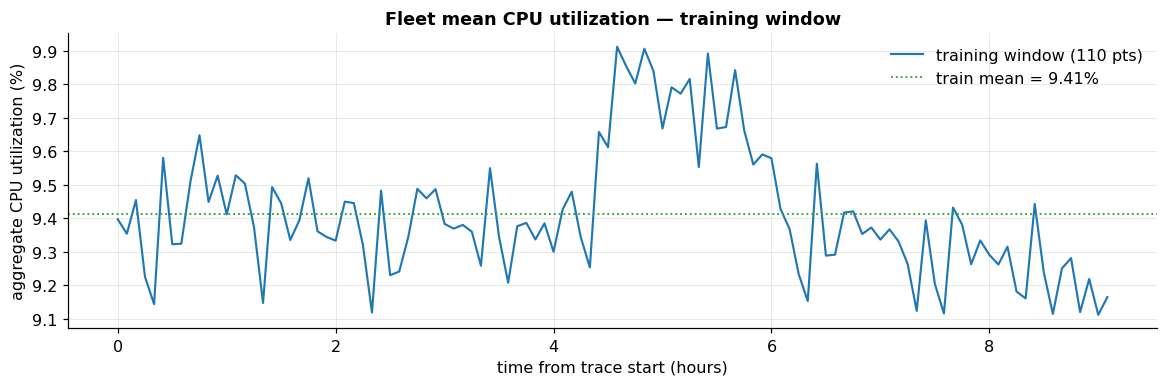

train:  mean 9.414%  std 0.194 pp  min 9.112  max 9.912  (CV 2.06%)


In [8]:
fig, ax = plt.subplots(figsize=(10.5, 3.4), constrained_layout=True)
ax.plot(agg_train.index / 3600, agg_train.values, color=C_TRAIN, lw=1.4,
        label="training window (110 pts)")
ax.axhline(agg_train.mean(), color=C_ACC, lw=1.2, ls=":",
           label=f"train mean = {agg_train.mean():.2f}%")
ax.set_xlabel("time from trace start (hours)")
ax.set_ylabel("aggregate CPU utilization (%)")
ax.set_title("Fleet mean CPU utilization — training window")
ax.legend()
save_fig(fig, "fig05_aggregate_series.png")
plt.show()

print(f"train:  mean {agg_train.mean():.3f}%  std {agg_train.std():.3f} pp  "
      f"min {agg_train.min():.3f}  max {agg_train.max():.3f}  (CV {agg_train.std()/agg_train.mean():.2%})")

The fleet mean oscillates in a narrow band around 9.4% with a standard deviation of
only 0.19 pp (coefficient of variation ≈ 2%). Two things stand out: a **sustained
above-average plateau around t ≈ 4.5–5.7 h**, and the fact that the **training window
ends at the bottom of the range** (the last training values sit near the 9.11% minimum).

> **Operational reading.** The aggregate's stability is what makes short-horizon
> capacity planning tractable: at this fleet size, per-VM noise averages out and the
> *level* moves slowly. But the trailing dip matters operationally — a forecaster that
> anchors on the most recent values (persistence) would enter the 2-hour horizon biased
> low, exactly when a capacity planner would under-provision. This motivates validating
> baselines that smooth over a longer window (moving average / exponential smoothing)
> rather than assuming "last value wins".

## 7. Peak and low-demand periods

Peaks and troughs below are identified **on the training window only**, because the
peak-detection threshold is part of the evaluation design (peak-period error is a
reported metric in `ASSIGNMENT.md` §3F). We use a rolling z-score definition: a timestamp
is *peak* if its value is ≥ mean + 1σ of the training series, and *low* if ≤ mean − 1σ.

saved figures/fig06_peaks_lows.png


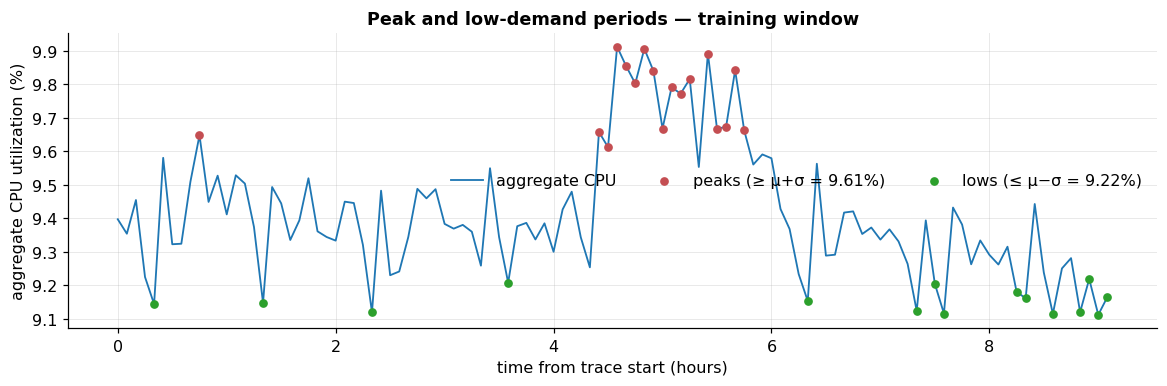

peak timestamps: 17 (15% of train) | low timestamps: 15 (14%)
top-5 peaks:
  t =  16500 s (4.58 h): 9.912%
  t =  17400 s (4.83 h): 9.906%
  t =  19500 s (5.42 h): 9.892%
  t =  16800 s (4.67 h): 9.854%
  t =  20400 s (5.67 h): 9.842%
peak timestamps span t = 2700–20700 s (0.8–5.8 h)


In [9]:
mu, sd = agg_train.mean(), agg_train.std()
peaks = agg_train[agg_train >= mu + sd]
lows = agg_train[agg_train <= mu - sd]

fig, ax = plt.subplots(figsize=(10.5, 3.4), constrained_layout=True)
ax.plot(agg_train.index / 3600, agg_train.values, color=C_TRAIN, lw=1.2, label="aggregate CPU")
ax.scatter(peaks.index / 3600, peaks.values, color="#c44e52", zorder=3, s=22,
           label=f"peaks (≥ μ+σ = {mu+sd:.2f}%)")
ax.scatter(lows.index / 3600, lows.values, color=C_ACC, zorder=3, s=22,
           label=f"lows (≤ μ−σ = {mu-sd:.2f}%)")
ax.set_xlabel("time from trace start (hours)")
ax.set_ylabel("aggregate CPU utilization (%)")
ax.set_title("Peak and low-demand periods — training window")
ax.legend(ncol=3)
save_fig(fig, "fig06_peaks_lows.png")
plt.show()

peak_share = len(peaks) / len(agg_train)
print(f"peak timestamps: {len(peaks)} ({peak_share:.0%} of train) | low timestamps: {len(lows)} ({len(lows)/len(agg_train):.0%})")
print("top-5 peaks:")
for t, v in peaks.nlargest(5).items():
    print(f"  t = {t:>6} s ({t/3600:.2f} h): {v:.3f}%")
# are peaks clustered in time?
print(f"peak timestamps span t = {peaks.index.min()}–{peaks.index.max()} s "
      f"({peaks.index.min()/3600:.1f}–{peaks.index.max()/3600:.1f} h)")

Peaks are not uniformly scattered — they cluster in the middle of the window
(t ≈ 4.3–5.7 h), forming the plateau seen in §6, while the lows concentrate at the very
end of the training window. There is **no periodic pattern** in the peak spacing (the
window is too short to contain one), so "seasonal" peak anticipation is not available;
peaks must be anticipated from the *recent trajectory*.

> **Operational reading.** For autoscaling the relevant question is not just "how high is
> the peak" but "how fast do we get there". The plateau here builds over ~30–45 minutes
> (6–9 five-minute steps) and decays more slowly — comfortably inside the reaction time
> of a 5-minute autoscaler but too fast for weekly capacity reviews. This justifies
> *predictive* scaling with a 2-hour horizon rather than purely reactive thresholds.

## 8. Segment dynamics: workload differences over time

How do the three workload categories behave over time? Segment means are computed from the
**training-window readings only**, and every statistic below (means, volatilities,
autocorrelations) is a training-window quantity.

saved figures/fig07_segment_series.png


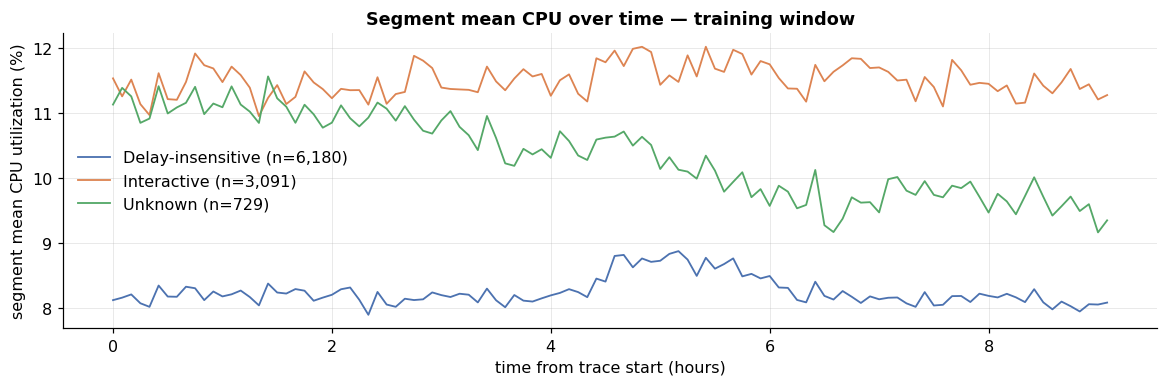

,segment,mean %,std (pp),CV,lag-1 autocorr (train)
0,Delay-insensitive,8.26,0.217,0.0263,0.801
1,Interactive,11.51,0.243,0.0212,0.436
2,Unknown,10.35,0.629,0.0607,0.916
3,FLEET aggregate,9.41,0.194,0.0206,0.667


In [10]:
cpu_seg = cpu_train.merge(meta[["vm_id", "vm_category"]], on="vm_id", how="left")
seg_ts = cpu_seg.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()

fig, ax = plt.subplots(figsize=(10.5, 3.4), constrained_layout=True)
for i, cat in enumerate(["Delay-insensitive", "Interactive", "Unknown"]):
    ax.plot(seg_ts.index / 3600, seg_ts[cat], lw=1.2, color=C_CAT[i],
            label=f"{cat} (n={ (meta['vm_category']==cat).sum():,})")
ax.set_xlabel("time from trace start (hours)")
ax.set_ylabel("segment mean CPU utilization (%)")
ax.set_title("Segment mean CPU over time — training window")
ax.legend()
save_fig(fig, "fig07_segment_series.png")
plt.show()

rows = []
for cat in ["Delay-insensitive", "Interactive", "Unknown"]:
    s_tr = seg_ts[cat]
    rows.append({
        "segment": cat,
        "mean %": round(s_tr.mean(), 2),
        "std (pp)": round(s_tr.std(), 3),
        "CV": round(s_tr.std() / s_tr.mean(), 4),
        "lag-1 autocorr (train)": round(s_tr.autocorr(1), 3),
    })
agg_row = {"segment": "FLEET aggregate", "mean %": round(agg_train.mean(), 2),
           "std (pp)": round(agg_train.std(), 3),
           "CV": round(agg_train.std()/agg_train.mean(), 4),
           "lag-1 autocorr (train)": round(agg_train.autocorr(1), 3)}
display(pd.DataFrame(rows + [agg_row]))

Interactive workloads run ~3 pp hotter than Delay-insensitive ones on average, and
the **Unknown** segment (7% of VMs) is by far the most volatile relative to its level
(CV ≈ 6% vs ≈ 2% for the others). Every segment series is positively autocorrelated, so
short-horizon momentum exists in all three.

> **Operational reading.** Segment mix is the handle a planner actually controls: because
> categories have different levels *and* different volatilities, a demand shift of a few
> percent of VMs between categories moves the fleet mean even when total VM count is
> fixed. Monitoring the *composition* of demand — not just its total — gives early
> warning of utilization shifts. The volatile Unknown segment is the natural first target
> for stricter per-segment safety margins.

## 9. Outliers and statistical patterns

We examine (a) unusual timestamps of the aggregate, via a rolling-window z-score, and
(b) unusual VMs, via their lifetime statistics. All thresholds are computed on the
training window only.

saved figures/fig08_outliers.png


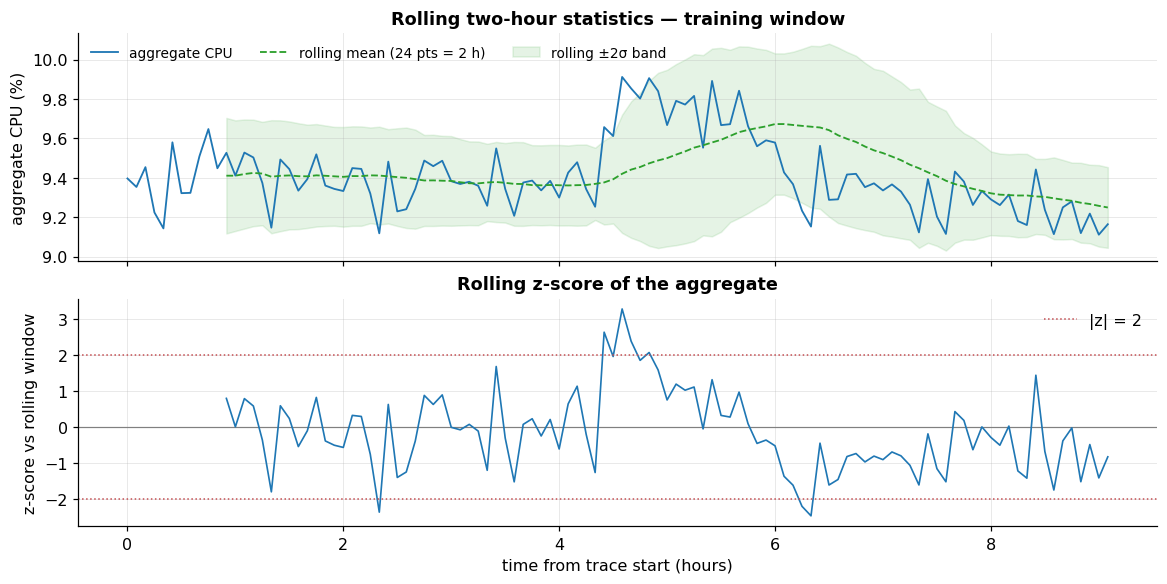

training timestamps with |z| > 2 vs trailing 2-h window: 7 of 99


,|z|
timestamp,
16500,3.27
15900,2.63
22800,2.47
16800,2.38
8400,2.37



hottest VM lifetime means: 80.4%–99.2% (172 VMs above 50% lifetime mean)


In [11]:
roll = agg_train.rolling(24, min_periods=12)
z = (agg_train - roll.mean()) / roll.std()

fig, axes = plt.subplots(2, 1, figsize=(10.5, 5.2), sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(agg_train.index / 3600, agg_train.values, color=C_TRAIN, lw=1.2, label="aggregate CPU")
ax.plot(roll.mean().index / 3600, roll.mean().values, color=C_ACC, lw=1.2, ls="--",
        label="rolling mean (24 pts = 2 h)")
ax.fill_between(roll.mean().index / 3600,
                (roll.mean() - 2 * roll.std()).values,
                (roll.mean() + 2 * roll.std()).values,
                color=C_ACC, alpha=0.12, label="rolling ±2σ band")
ax.set_ylabel("aggregate CPU (%)")
ax.set_title("Rolling two-hour statistics — training window")
ax.legend(ncol=3, fontsize=9)

ax = axes[1]
ax.axhline(0, color="grey", lw=0.8)
ax.plot(z.index / 3600, z.values, color=C_TRAIN, lw=1.1)
ax.axhline(2, color="#c44e52", lw=1, ls=":", label="|z| = 2")
ax.axhline(-2, color="#c44e52", lw=1, ls=":")
ax.set_xlabel("time from trace start (hours)")
ax.set_ylabel("z-score vs rolling window")
ax.set_title("Rolling z-score of the aggregate")
ax.legend()
save_fig(fig, "fig08_outliers.png")
plt.show()

n_out = int((z.abs() > 2).sum())
print(f"training timestamps with |z| > 2 vs trailing 2-h window: {n_out} of {z.notna().sum()}")
display(z.abs().nlargest(5).round(2).to_frame("|z|"))

# VM-level outliers via metadata lifetime statistics (descriptive only)
hot = meta["avg_cpu"].nlargest(25)
print(f"\nhottest VM lifetime means: {hot.min():.1f}%–{hot.max():.1f}% "
      f"({(meta['avg_cpu'] > 50).sum()} VMs above 50% lifetime mean)")

The aggregate shows **no abrupt anomalies** — the strongest deviation from its
trailing two-hour statistics is |z| ≈ 2.4, and excursions beyond |z| = 2 are rare and
short. The elevated plateau of §6–7 appears here as a stretch of positive z-scores, i.e.
a *sustained shift*, not a spike. At the VM level, a small group of VMs (dozens) sustain
lifetime means above 50%.

> **Operational reading.** For capacity planning the absence of spikes is good news: the
> aggregate demand the fleet must serve evolves smoothly, so a modest safety margin
> (analyzed in the evaluation notebook) can cover the forecast error. The hot-VM tail is
> a *placement* problem rather than a *capacity* problem — those VMs need dedicated
> headroom or isolation on their hosts, which aggregate forecasts do not see.

## 10. Correlation and temporal dependencies

The autocorrelation structure is the single most decision-relevant statistic for model
selection, so the ACF/PACF below use the **training window only**. We also quantify how
much of the aggregate's movement is driven by its heaviest VMs.

saved figures/fig09_acf_pacf.png


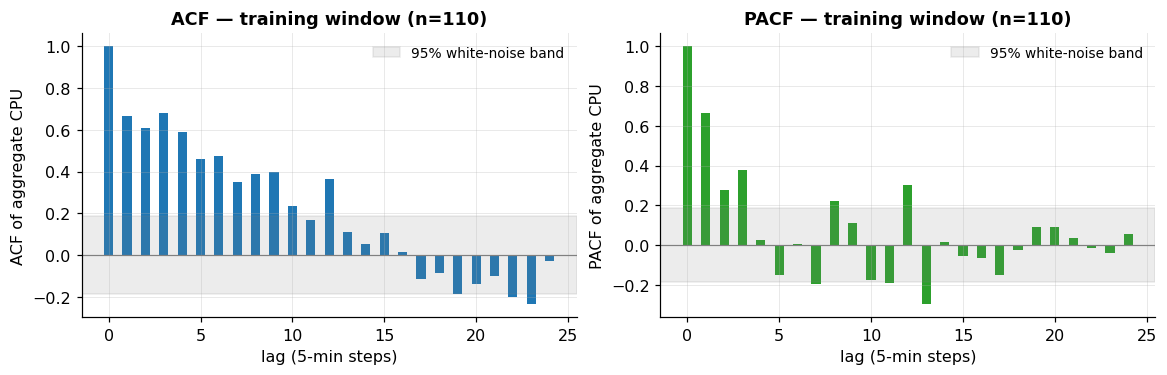

ACF lags 1–8: [0.667 0.606 0.681 0.59  0.461 0.477 0.35  0.391]
differenced-series lag-1 autocorr: -0.415


In [12]:
def acf(x: pd.Series, nlags: int) -> np.ndarray:
    x = x - x.mean()
    return np.array([1.0] + [x.autocorr(k) for k in range(1, nlags + 1)])

nlags = 24
acf_vals = acf(agg_train, nlags)
# PACF via Yule-Walker (statsmodels) on the training window
from statsmodels.tsa.stattools import pacf as sm_pacf
pacf_vals = sm_pacf(agg_train, nlags=nlags, method="ywm")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3), constrained_layout=True)
for ax, vals, name, ci_col in (
    (axes[0], acf_vals, "ACF", C_TRAIN),
    (axes[1], pacf_vals, "PACF", C_ACC),
):
    ax.bar(range(len(vals)), vals, color=ci_col, width=0.5)
    ci = 1.96 / np.sqrt(len(agg_train))
    ax.axhspan(-ci, ci, color="grey", alpha=0.15, label="95% white-noise band")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("lag (5-min steps)")
    ax.set_ylabel(f"{name} of aggregate CPU")
    ax.set_title(f"{name} — training window (n=110)")
    ax.legend(fontsize=9)
save_fig(fig, "fig09_acf_pacf.png")
plt.show()

print("ACF lags 1–8:", np.round(acf_vals[1:9], 3))
print("differenced-series lag-1 autocorr:", round(agg_train.diff().autocorr(1), 3))

saved figures/fig10_heavy_hitters.png


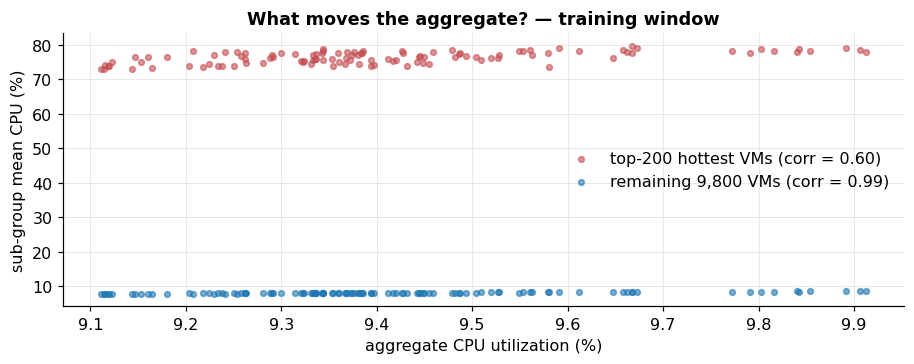

corr matrix of reading-level fields (all 1.34 M rows):


,min_cpu,max_cpu,avg_cpu
min_cpu,1.000,0.641,0.929
max_cpu,0.641,1.000,0.821
avg_cpu,0.929,0.821,1.000


In [13]:
# How much of the aggregate's movement do the heaviest VMs drive?
# (VM ranking and sub-series both from the training window only)
vm_mean = cpu_train.groupby("vm_id")["avg_cpu"].mean()
top200 = vm_mean.nlargest(200).index
heavy = cpu_train[cpu_train["vm_id"].isin(top200)].groupby("timestamp")["avg_cpu"].mean()
rest = cpu_train[~cpu_train["vm_id"].isin(top200)].groupby("timestamp")["avg_cpu"].mean()

fig, ax = plt.subplots(figsize=(8.2, 3.2), constrained_layout=True)
ax.scatter(agg_train.values, heavy.values, s=14, alpha=0.6,
           color="#c44e52", label=f"top-200 hottest VMs (corr = {agg_train.corr(heavy):.2f})")
ax.scatter(agg_train.values, rest.values, s=14, alpha=0.6,
           color=C_TRAIN, label=f"remaining 9,800 VMs (corr = {agg_train.corr(rest):.2f})")
ax.set_xlabel("aggregate CPU utilization (%)")
ax.set_ylabel("sub-group mean CPU (%)")
ax.set_title("What moves the aggregate? — training window")
ax.legend()
save_fig(fig, "fig10_heavy_hitters.png")
plt.show()

print("corr matrix of reading-level fields (all 1.34 M rows):")
display(cpu_train[["min_cpu", "max_cpu", "avg_cpu"]].corr().round(3))

The training-window ACF decays smoothly from 0.67 at lag 1 to ≈ 0.39 by lag 8 and
stays mildly positive out to lag 24 — a **persistent, slowly mean-reverting** series with
no significant single-lag signature (PACF significant only at low lags). The differenced
series has negative lag-1 autocorrelation (−0.16), confirming mild mean reversion rather
than a pure random walk. The aggregate correlates 0.99 with the mean of the remaining
9,800 VMs but only ≈ 0.49 with the top-200 hottest VMs: the *bulk* of the fleet moves the
aggregate, while the hot tail (2% of VMs, 16% of total CPU) adds comparatively
independent noise.

> **Operational reading.** Practical consequences: (i) forecastable *memory* exists —
> recent values carry information several steps ahead, favouring smoothing models
> (moving average / exponential smoothing) and regularized autoregressions over both
> naive persistence and calendar models; (ii) the useful signal decays within roughly
> 2–3 hours, matching the 2-hour forecast horizon; beyond that, forecasts should relax
> toward the historical mean. (iii) Because thousands of VMs contribute to every
> aggregate movement, no single tenant's behaviour dominates — aggregate forecasts
> degrade gracefully even if individual VMs misbehave.

## 11. EDA summary — findings that drive the modelling design

| # | Finding (measured on the training window) | Modelling / operational consequence |
|---|---|---|
| 1 | `active_vm_count` constant at 10,000 (complete traces only, no churn in window) | Constant forecast is optimal for this target; no ML complexity warranted. Document curation artefact honestly. |
| 2 | Window is 11.08 h — no identifiable daily/weekly seasonality | No calendar or seasonal features; short-memory models only. |
| 3 | Aggregate CPU: mean 9.41%, σ = 0.19 pp, CV ≈ 2% | Forecasting target is a stable level with small fluctuations; expect small absolute errors. |
| 4 | Lag-1 autocorr 0.67, slow decay, mild mean reversion | Persistence is beatable; smoothing / autoregressive models are the right family. |
| 5 | Training window ends near the series minimum (9.11%) | Pure persistence will enter the horizon biased low — a concrete failure mode to test. |
| 6 | Peaks cluster in a mid-window plateau; no periodicity | Peak-period error must be reported separately (ASSIGNMENT §3F); peaks anticipated from trajectory, not calendar. |
| 7 | Between-VM variance ≫ within-VM variance; heavy right tail | Aggregate is stable by averaging; per-VM tail is a placement concern, not capacity. |
| 8 | Segments differ in level and volatility (Unknown most volatile) | Segment-augmented models are worth testing as candidates (with leakage-safe future-segment handling — see notebook 02). |
| 9 | Metadata lifetime CPU stats & deletion timestamps are future info | Excluded from features by design; used descriptively only. |

**Scope note.** Every number in this notebook is computed on the 110-timestamp training
window; the sealed holdout appears only in `03_evaluation.ipynb`.

**Next steps.** `02_forecasting.ipynb` implements the leakage-safe validation design,
compares baselines and candidate models, and selects one configuration per target;
`03_evaluation.ipynb` evaluates the frozen models on the untouched holdout, analyses
errors by horizon and load level, and derives the capacity-planning recommendation.